# 05a Classic ML: VertexFleet demand and failure models

Two prediction tasks, one notebook:

* **Demand (regression):** trips per zone per hour.
* **Failure (classification):** will this vehicle fail within 7 days?

Sections follow the course topics: 1 foundations, 2 regression, 3 classification and SVM, 4 evaluation and tuning, 5 feature engineering and PCA, 6 ensembles, 7 unsupervised and latent models, then explainability (SHAP), experiment tracking (MLflow) and saving the selected models.

**Rule for the whole notebook:** the test set is touched only to report final numbers. Every model choice is made with time-ordered cross-validation on the training period, like studying from practice exams and opening the real exam only once.

In [1]:
# Setup: project root, src/ and 05_ml/ importable, config and seed
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "configs" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "05_ml"))
from settings import load_config, set_seed
CFG = load_config()
SEED = set_seed()
ART = CFG["paths"]["artifacts"]
ART.mkdir(parents=True, exist_ok=True)
print("Ready:", ROOT, "| seed:", SEED)

Ready: c:\Users\David.satizabal001\Documents\ML-1 | seed: 42


In [2]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import (GradientBoostingRegressor, HistGradientBoostingClassifier, IsolationForest,
                              RandomForestClassifier, StackingClassifier, VotingClassifier)
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (adjusted_rand_score, average_precision_score, brier_score_loss, f1_score,
                             mean_absolute_error, mean_squared_error, precision_score, r2_score,
                             recall_score, roc_auc_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, cross_val_score,
                                     learning_curve, validation_curve)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

import preprocess as pp
warnings.filterwarnings("ignore", category=FutureWarning)
EXPERIMENTS = []   # every model run lands here, then goes to MLflow and a CSV

def log_run(task, model, params=None, **metrics):
    EXPERIMENTS.append({"task": task, "model": model, "params": json.dumps(params or {}), **metrics})

## Load data

Tries the saved files first; when one is missing, asks for it (file upload in Colab, file picker in VS Code) instead of erroring.

In [3]:
SYN = CFG["paths"]["data_synthetic"]

def load_csv(name, parse_dates=None):
    path = SYN / f"{name}.csv"
    if path.exists():
        return pd.read_csv(path, parse_dates=parse_dates)
    print(f"{path} not found; please choose the file.")
    try:
        from google.colab import files
        import io
        uploaded = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(uploaded.values()))), parse_dates=parse_dates)
    except ImportError:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
        chosen = filedialog.askopenfilename(title=f"Select {name}.csv", filetypes=[("CSV", "*.csv")])
        root.destroy()
        return pd.read_csv(chosen, parse_dates=parse_dates)

telemetry = load_csv("telemetry", ["date"])
trips = load_csv("trips", ["timestamp"])
print(telemetry.shape, trips.shape)

(4500, 13) (17280, 7)


## 1. Foundations: features, splits, baselines

Feature code lives in `05_ml/preprocess.py` so the agent can reuse it live. Every feature looks only at the current day or hour and the past.

* **Failure:** raw telemetry plus 7-day rolling features (average vibration, how much it changed in a week, rainy days, km driven).
* **Demand:** hour of day as a circle (sin/cos, so 23:00 sits next to 00:00), weekend flag, weather, demand 24 hours and 168 hours ago, and the last 24 hours' average.

Both use the same cutoff as Phase 1 (simulation start + 70 days), so numbers compare directly.

In [4]:
CUTOFF = pp.cutoff_date(telemetry.date.min(), CFG["sim_details"]["train_days"])

fail_df = pp.build_failure_features(telemetry)
f_train, f_test = pp.time_split(fail_df, "date", CUTOFF)
f_train = f_train.sort_values(["date", "vehicle_id"])           # time order for TimeSeriesSplit
Xf_tr, yf_tr = f_train[pp.FAILURE_FEATURES], f_train[pp.FAILURE_TARGET]
Xf_te, yf_te = f_test[pp.FAILURE_FEATURES], f_test[pp.FAILURE_TARGET]

dem_df = pp.build_demand_features(trips)
d_train, d_test = pp.time_split(dem_df, "timestamp", CUTOFF)
d_train = d_train.sort_values(["timestamp", "zone"])
DEM_COLS = pp.DEMAND_NUMERIC + pp.DEMAND_CATEGORICAL
Xd_tr, yd_tr = d_train[DEM_COLS], d_train[pp.DEMAND_TARGET]
Xd_te, yd_te = d_test[DEM_COLS], d_test[pp.DEMAND_TARGET]

TSCV = TimeSeriesSplit(n_splits=5)   # each fold trains on the past and validates on the next block
print(f"Failure: train {len(f_train)} ({yf_tr.mean():.1%} positive), test {len(f_test)} ({yf_te.mean():.1%} positive)")
print(f"Demand:  train {len(d_train)}, test {len(d_test)}")
print("Phase 1 baselines to beat: demand RMSE 3.527 | failure logistic recall 0.709, ROC AUC 0.865")

Failure: train 3500 (16.9% positive), test 1000 (14.1% positive)
Demand:  train 12096, test 3840
Phase 1 baselines to beat: demand RMSE 3.527 | failure logistic recall 0.709, ROC AUC 0.865


## 2. Advanced regression: demand forecast

Five regressors, same features: plain linear, polynomial (degree 2, adds interactions such as rain x evening), Ridge (L2 penalty shrinks weights), Lasso (L1 penalty can zero weights out), and gradient boosting (many small trees, each fixing the last one's mistakes).

In [5]:
def demand_prep(poly=False):
    num = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False)) if poly else StandardScaler()
    return ColumnTransformer([("num", num, pp.DEMAND_NUMERIC),
                              ("zone", OneHotEncoder(handle_unknown="ignore"), pp.DEMAND_CATEGORICAL)])

regressors = {
    "Linear": make_pipeline(demand_prep(), LinearRegression()),
    "Polynomial (deg 2) + Ridge": make_pipeline(demand_prep(poly=True), Ridge(alpha=1.0)),
    "Ridge": make_pipeline(demand_prep(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(demand_prep(), Lasso(alpha=0.01, max_iter=5000)),
    "Gradient boosting": make_pipeline(demand_prep(), GradientBoostingRegressor(random_state=SEED)),
}
reg_rows, reg_preds = [], {}
for name, model in regressors.items():
    cv_rmse = -cross_val_score(model, Xd_tr, yd_tr, cv=TSCV, scoring="neg_root_mean_squared_error").mean()
    model.fit(Xd_tr, yd_tr)
    pred = model.predict(Xd_te)
    reg_preds[name] = pred
    row = {"model": name, "cv_rmse": cv_rmse, "test_mse": mean_squared_error(yd_te, pred),
           "test_rmse": mean_squared_error(yd_te, pred) ** 0.5, "test_mae": mean_absolute_error(yd_te, pred),
           "test_r2": r2_score(yd_te, pred)}
    reg_rows.append(row)
    log_run("demand", name, **{k: v for k, v in row.items() if k != "model"})
reg_table = pd.DataFrame(reg_rows).set_index("model").round(3).sort_values("cv_rmse")
display(reg_table)
BEST_REG = reg_table.index[0]
print("Selected by cross-validation:", BEST_REG)

,cv_rmse,test_mse,test_rmse,test_mae,test_r2
model,,,,,
Gradient boosting,3.369,10.594,3.255,2.489,0.746
Polynomial (deg 2) + Ridge,3.620,12.565,3.545,2.738,0.698
Ridge,3.978,15.239,3.904,2.985,0.634
Linear,3.978,15.239,3.904,2.985,0.634
Lasso,3.979,15.235,3.903,2.982,0.634


Selected by cross-validation: Gradient boosting


**Residual analysis.** Residual = actual minus predicted. A good model's residuals look like random noise centered on zero. A fan shape (bigger errors when demand is bigger) is expected for count data, because busier hours vary more.

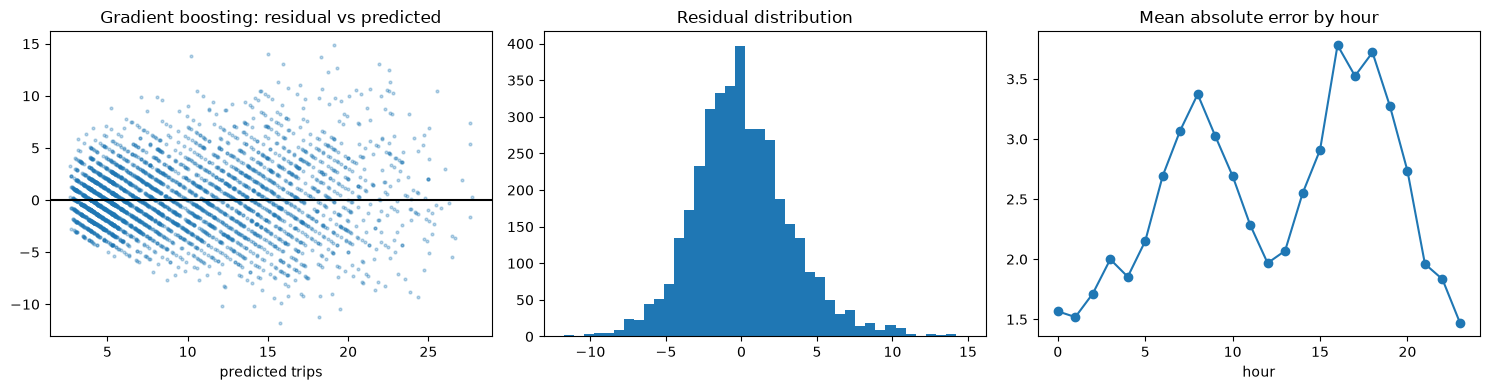

Residual mean 0.039 (close to 0 means no systematic bias)


In [6]:
res = yd_te.to_numpy() - reg_preds[BEST_REG]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(reg_preds[BEST_REG], res, s=4, alpha=0.3); axes[0].axhline(0, color="k")
axes[0].set_title(f"{BEST_REG}: residual vs predicted"); axes[0].set_xlabel("predicted trips")
axes[1].hist(res, bins=40); axes[1].set_title("Residual distribution")
pd.Series(np.abs(res), index=d_test.hour.to_numpy()).groupby(level=0).mean().plot(ax=axes[2], marker="o")
axes[2].set_title("Mean absolute error by hour"); axes[2].set_xlabel("hour")
plt.tight_layout(); plt.show()
print(f"Residual mean {res.mean():.3f} (close to 0 means no systematic bias)")

## 3. Advanced classification and SVM: will the vehicle fail within 7 days?

Five classifiers. About 1 row in 6 is a failure, so a lazy model could score 83% accuracy by always saying "no". We therefore judge by **recall** (failures caught), **precision** (alarms that were real), F1, ROC AUC, and **PR AUC** (average precision, the most honest single number for rare positives). Models that support it use `class_weight="balanced"`, which tells the model a missed failure costs more than a false alarm.

In [7]:
def scaled(model):
    return make_pipeline(StandardScaler(), model)

classifiers = {
    "Logistic (balanced)": scaled(LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)),
    "k-NN (k=15)": scaled(KNeighborsClassifier(n_neighbors=15)),
    "Decision tree (balanced)": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEED),
    "Gaussian naive Bayes": scaled(GaussianNB()),
    "SVM RBF (balanced)": scaled(SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=SEED)),
}

def scores_of(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def clf_metrics(y, pred, score):
    return {"precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, score), "pr_auc": average_precision_score(y, score)}

clf_rows = []
for name, model in classifiers.items():
    cv_ap = cross_val_score(model, Xf_tr, yf_tr, cv=TSCV, scoring="average_precision").mean()
    model.fit(Xf_tr, yf_tr)
    m = clf_metrics(yf_te, model.predict(Xf_te), scores_of(model, Xf_te))
    clf_rows.append({"model": name, "cv_pr_auc": cv_ap, **m})
    log_run("failure", name, cv_pr_auc=cv_ap, **m)
clf_table = pd.DataFrame(clf_rows).set_index("model").round(3).sort_values("cv_pr_auc", ascending=False)
display(clf_table)

,cv_pr_auc,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Gaussian naive Bayes,0.627,0.582,0.603,0.592,0.856,0.632
Logistic (balanced),0.597,0.508,0.688,0.584,0.868,0.659
k-NN (k=15),0.596,0.670,0.461,0.546,0.858,0.575
Decision tree (balanced),0.520,0.344,0.702,0.462,0.757,0.507
SVM RBF (balanced),0.493,0.432,0.674,0.526,0.857,0.541


**Calibration.** A calibrated model's "70%" really means 7 out of 10 such vehicles fail. That matters here because the entailment stage compares model support with a threshold (0.8), so the probabilities must mean what they say. SVMs output distances, not probabilities, so we wrap them in `CalibratedClassifierCV`. Brier score: lower is better.

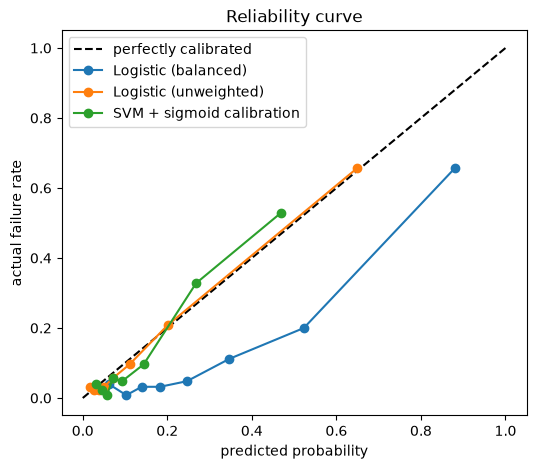

,brier
model,
Logistic (balanced),0.1129
Logistic (unweighted),0.0763
SVM + sigmoid calibration,0.0911


Balanced class weights raise recall but push probabilities up, so they read as over-confident.


In [8]:
calibrated = {
    "Logistic (balanced)": classifiers["Logistic (balanced)"],
    "Logistic (unweighted)": scaled(LogisticRegression(max_iter=2000, random_state=SEED)).fit(Xf_tr, yf_tr),
    "SVM + sigmoid calibration": CalibratedClassifierCV(scaled(SVC(kernel="rbf", class_weight="balanced",
                                                                  random_state=SEED)),
                                                       method="sigmoid", cv=TSCV).fit(Xf_tr, yf_tr),
}
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
cal_rows = []
for name, model in calibrated.items():
    p = model.predict_proba(Xf_te)[:, 1]
    frac, mean_pred = calibration_curve(yf_te, p, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", label=name)
    cal_rows.append({"model": name, "brier": brier_score_loss(yf_te, p)})
ax.set_xlabel("predicted probability"); ax.set_ylabel("actual failure rate"); ax.legend(); ax.set_title("Reliability curve")
plt.show()
display(pd.DataFrame(cal_rows).set_index("model").round(4))
print("Balanced class weights raise recall but push probabilities up, so they read as over-confident.")

## 4. Model evaluation and optimization

**Learning curve:** does more data help? If training and validation scores are still far apart at full size, more data would help. If they have converged, the model needs better features instead.

**Validation curve:** how one hyperparameter (SVM `C`, how strictly it fits the training data) trades underfitting against overfitting.

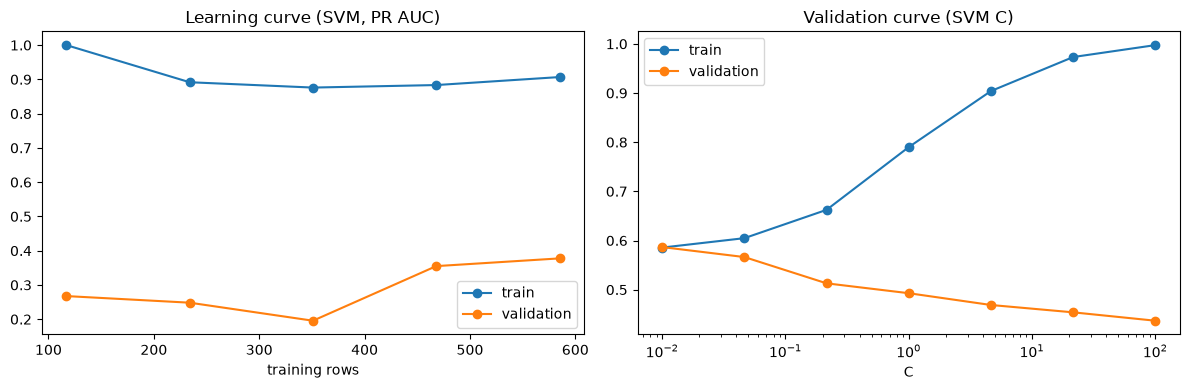

Best C on validation: 0.01


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
svm = scaled(SVC(kernel="rbf", class_weight="balanced", random_state=SEED))
sizes, tr_sc, va_sc = learning_curve(svm, Xf_tr, yf_tr, cv=TSCV, scoring="average_precision",
                                     train_sizes=np.linspace(0.2, 1.0, 5))
axes[0].plot(sizes, tr_sc.mean(1), marker="o", label="train"); axes[0].plot(sizes, va_sc.mean(1), marker="o", label="validation")
axes[0].set_title("Learning curve (SVM, PR AUC)"); axes[0].set_xlabel("training rows"); axes[0].legend()

C_range = np.logspace(-2, 2, 7)
tr_sc, va_sc = validation_curve(svm, Xf_tr, yf_tr, param_name="svc__C", param_range=C_range,
                                cv=TSCV, scoring="average_precision")
axes[1].semilogx(C_range, tr_sc.mean(1), marker="o", label="train"); axes[1].semilogx(C_range, va_sc.mean(1), marker="o", label="validation")
axes[1].set_title("Validation curve (SVM C)"); axes[1].set_xlabel("C"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Best C on validation: {C_range[va_sc.mean(1).argmax()]:.2f}")

**Three ways to tune the same model** (histogram gradient boosting, scored by cross-validated PR AUC):

* **Grid search:** tries every combination in a small grid. Thorough but slow as grids grow.
* **Random search:** samples combinations at random. Often as good with fewer tries.
* **Bayesian (Optuna):** learns from earlier tries which regions look promising and samples there next, like a treasure hunter who digs near the last good find.

In [10]:
hgb = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)
tune_rows = []

grid = {"learning_rate": [0.03, 0.1], "max_depth": [3, 6], "max_iter": [100, 300]}
t0 = time.perf_counter()
gs = GridSearchCV(hgb, grid, cv=TSCV, scoring="average_precision").fit(Xf_tr, yf_tr)
tune_rows.append({"method": "Grid search", "tries": len(gs.cv_results_["params"]), "cv_pr_auc": gs.best_score_,
                  "seconds": time.perf_counter() - t0, "best_params": gs.best_params_})

dist = {"learning_rate": np.logspace(-2, -0.5, 20), "max_depth": [2, 3, 4, 5, 6, 8],
        "max_iter": [100, 200, 300, 400], "l2_regularization": np.logspace(-3, 1, 10)}
t0 = time.perf_counter()
rs = RandomizedSearchCV(hgb, dist, n_iter=8, cv=TSCV, scoring="average_precision", random_state=SEED).fit(Xf_tr, yf_tr)
tune_rows.append({"method": "Random search", "tries": 8, "cv_pr_auc": rs.best_score_,
                  "seconds": time.perf_counter() - t0, "best_params": rs.best_params_})

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective(trial):
        params = {"learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                  "max_depth": trial.suggest_int("max_depth", 2, 8),
                  "max_iter": trial.suggest_int("max_iter", 100, 400, step=50),
                  "l2_regularization": trial.suggest_float("l2_regularization", 1e-3, 10, log=True)}
        return cross_val_score(clone(hgb).set_params(**params), Xf_tr, yf_tr, cv=TSCV,
                               scoring="average_precision").mean()
    t0 = time.perf_counter()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=8)
    tune_rows.append({"method": "Bayesian (Optuna TPE)", "tries": 8, "cv_pr_auc": study.best_value,
                      "seconds": time.perf_counter() - t0, "best_params": study.best_params})
except ImportError:
    print("optuna not installed: pip install optuna   (skipping Bayesian search)")

tune_table = pd.DataFrame(tune_rows).set_index("method")
display(tune_table.round(4))
for _, r in tune_table.iterrows():
    log_run("failure-tuning", r.name, params={k: float(v) for k, v in r.best_params.items()}, cv_pr_auc=r.cv_pr_auc)
BEST_HGB_PARAMS = tune_table.sort_values("cv_pr_auc", ascending=False).best_params.iloc[0]
print("Best tuned parameters:", BEST_HGB_PARAMS)

c:\Users\David.satizabal001\Documents\ML-1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,tries,cv_pr_auc,seconds,best_params
method,,,,
Grid search,8,0.6249,23.9685,"{'learning_rate': 0.03, 'max_depth': 3, 'max_i..."
Random search,8,0.6167,24.5298,"{'max_iter': 100, 'max_depth': 8, 'learning_ra..."
Bayesian (Optuna TPE),8,0.6278,23.4676,"{'learning_rate': 0.01700037298921102, 'max_de..."


Best tuned parameters: {'learning_rate': 0.01700037298921102, 'max_depth': 3, 'max_iter': 100, 'l2_regularization': 2.9154431891537547}


## 5. Feature engineering and PCA

Three versions of the same logistic model: raw sensor values only, raw plus the 7-day engineered features, and PCA (compress the 14 scaled features into the few directions that hold 95% of the variation, like summarizing a long report into its key themes).

,n_inputs,cv_pr_auc,test_pr_auc,test_roc_auc
variant,,,,
Raw features,7,0.623,0.654,0.864
Raw + engineered,14,0.597,0.659,0.868
Raw + engineered -> PCA 95%,14,0.595,0.642,0.864


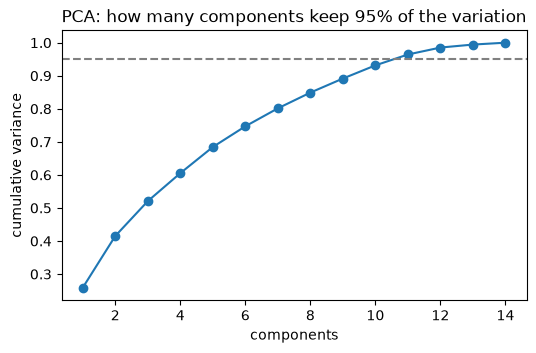

Components needed for 95%: 11 of 14


In [11]:
def evaluate_variant(name, model, cols):
    cv_ap = cross_val_score(model, f_train[cols], yf_tr, cv=TSCV, scoring="average_precision").mean()
    model.fit(f_train[cols], yf_tr)
    p = model.predict_proba(f_test[cols])[:, 1]
    log_run("failure-features", name, cv_pr_auc=cv_ap, test_pr_auc=average_precision_score(yf_te, p))
    return {"variant": name, "n_inputs": len(cols), "cv_pr_auc": cv_ap,
            "test_pr_auc": average_precision_score(yf_te, p), "test_roc_auc": roc_auc_score(yf_te, p)}

logit = lambda: LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)
fe_rows = [evaluate_variant("Raw features", scaled(logit()), pp.RAW_FAILURE_FEATURES),
           evaluate_variant("Raw + engineered", scaled(logit()), pp.FAILURE_FEATURES),
           evaluate_variant("Raw + engineered -> PCA 95%", make_pipeline(StandardScaler(), PCA(0.95, random_state=SEED), logit()),
                            pp.FAILURE_FEATURES)]
display(pd.DataFrame(fe_rows).set_index("variant").round(3))

pca = PCA(random_state=SEED).fit(StandardScaler().fit_transform(Xf_tr))
plt.figure(figsize=(6, 3.5))
plt.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.axhline(0.95, ls="--", color="gray"); plt.xlabel("components"); plt.ylabel("cumulative variance")
plt.title("PCA: how many components keep 95% of the variation"); plt.show()
print(f"Components needed for 95%: {np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.95) + 1} of {len(pca.explained_variance_ratio_)}")

## 6. Ensemble learning

* **Bagging (random forest):** many trees, each trained on a random resample; they vote. Reduces variance, like asking a crowd instead of one expert.
* **Boosting (tuned histogram gradient boosting):** trees built in sequence, each correcting the last. Usually the most accurate.
* **Stacking:** a logistic model learns how much to trust each base model.
* **Soft voting:** averages the base models' probabilities.

The trade-off: ensembles are more accurate and more robust to noise, but harder to explain than one logistic model or one shallow tree. Section 8 (SHAP) recovers explanations.

,cv_pr_auc,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Random forest (bagging),0.651,0.531,0.610,0.568,0.858,0.617
Stacking (logit + RF + HGB),0.651,0.708,0.482,0.574,0.857,0.621
Soft voting (logit + RF + HGB),0.646,0.497,0.702,0.582,0.866,0.646
Gradient boosting (tuned),0.628,0.403,0.794,0.535,0.854,0.615


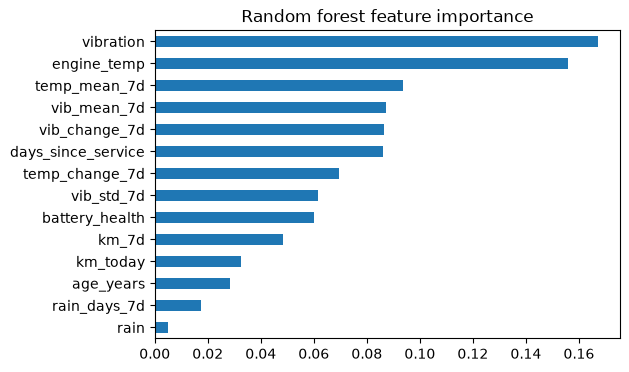

In [12]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=SEED, n_jobs=-1)
hgb_tuned = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED, **BEST_HGB_PARAMS)
base = [("logit", scaled(logit())), ("rf", clone(rf)), ("hgb", clone(hgb_tuned))]
ensembles = {
    "Random forest (bagging)": rf,
    "Gradient boosting (tuned)": hgb_tuned,
    "Stacking (logit + RF + HGB)": StackingClassifier(base, final_estimator=LogisticRegression(max_iter=1000), cv=5),
    "Soft voting (logit + RF + HGB)": VotingClassifier(base, voting="soft"),
}
ens_rows = []
for name, model in ensembles.items():
    cv_ap = cross_val_score(model, Xf_tr, yf_tr, cv=TSCV, scoring="average_precision").mean()
    model.fit(Xf_tr, yf_tr)
    m = clf_metrics(yf_te, model.predict(Xf_te), model.predict_proba(Xf_te)[:, 1])
    ens_rows.append({"model": name, "cv_pr_auc": cv_ap, **m})
    log_run("failure", name, cv_pr_auc=cv_ap, **m)
ens_table = pd.DataFrame(ens_rows).set_index("model").round(3).sort_values("cv_pr_auc", ascending=False)
display(ens_table)

imp = pd.Series(rf.feature_importances_, index=pp.FAILURE_FEATURES).sort_values()
imp.plot.barh(figsize=(6, 4), title="Random forest feature importance"); plt.show()

## 7. Unsupervised and latent models

Three questions without using the failure labels:

1. **Clustering:** do vehicles fall into natural usage groups? (k-means with silhouette score; Gaussian mixture with BIC.)
2. **Latent states:** if a Gaussian mixture is given only vibration and temperature, does it rediscover the hidden health states? (Adjusted Rand index: 1 = perfect match, 0 = random.)
3. **Anomaly detection:** does an Isolation Forest, trained only on what normal looks like, flag the Critical and Failed days?

In [13]:
profiles = telemetry.groupby("vehicle_id").agg(km_per_day=("km_today", "mean"), vibration=("vibration", "mean"),
                                               engine_temp=("engine_temp", "mean"), age_years=("age_years", "first"),
                                               rain_exposure=("rain", "mean"))
P = StandardScaler().fit_transform(profiles)
k_rows = []
for k in range(2, 7):
    km = KMeans(k, n_init=10, random_state=SEED).fit(P)
    gm = GaussianMixture(k, random_state=SEED).fit(P)
    k_rows.append({"k": k, "kmeans_silhouette": silhouette_score(P, km.labels_), "gmm_bic": gm.bic(P)})
k_table = pd.DataFrame(k_rows).set_index("k").round(3)
display(k_table)
best_k = int(k_table.kmeans_silhouette.idxmax())
profiles["cluster"] = KMeans(best_k, n_init=10, random_state=SEED).fit_predict(P)
print(f"Best k by silhouette: {best_k}. Cluster profiles:")
display(profiles.groupby("cluster").mean().round(2))

obs = telemetry[["vibration", "engine_temp"]]
latent = GaussianMixture(3, random_state=SEED).fit_predict(StandardScaler().fit_transform(obs))
ari = adjusted_rand_score(telemetry.true_state.replace({"Failed": "Critical"}), latent)
print(f"\nGMM latent states vs true hidden health: adjusted Rand index {ari:.3f}")

iso = IsolationForest(contamination=0.1, random_state=SEED).fit(f_train[pp.FAILURE_FEATURES])
f_test_anom = f_test.assign(anomaly=(iso.predict(Xf_te) == -1))
rate = f_test_anom.groupby("true_state").anomaly.mean().reindex(["Healthy", "Worn", "Critical", "Failed"]).round(3)
print("\nShare of days flagged as anomalous, by hidden state (higher for Critical/Failed is good):")
display(rate.to_frame("flagged_share"))
log_run("unsupervised", "KMeans", params={"k": best_k}, silhouette=float(k_table.kmeans_silhouette.max()))
log_run("unsupervised", "GMM latent health", adjusted_rand_index=ari)
log_run("unsupervised", "IsolationForest", flagged_critical_or_failed=float(rate[["Critical", "Failed"]].mean()),
        flagged_healthy=float(rate["Healthy"]))

,kmeans_silhouette,gmm_bic
k,,
2,0.269,2.585
3,0.249,68.701
4,0.233,107.270
5,0.237,177.267
6,0.249,242.858


Best k by silhouette: 2. Cluster profiles:


,km_per_day,vibration,engine_temp,age_years,rain_exposure
cluster,,,,,
0,147.79,2.39,89.65,4.88,0.33
1,150.38,2.86,91.91,4.42,0.33



GMM latent states vs true hidden health: adjusted Rand index 0.659

Share of days flagged as anomalous, by hidden state (higher for Critical/Failed is good):


,flagged_share
true_state,
Healthy,0.094
Worn,0.008
Critical,0.519
Failed,1.000


## Model selection

The failure model is chosen by **cross-validated PR AUC** across every classifier and ensemble above (never by test score). It is then calibrated so its probabilities can be compared with the entailment threshold.

In [14]:
all_clf = pd.concat([clf_table, ens_table]).sort_values("cv_pr_auc", ascending=False)
display(all_clf[["cv_pr_auc", "pr_auc", "roc_auc", "recall", "precision"]].head(5))
candidates = {**classifiers, **ensembles}
FAIL_NAME = all_clf.index[0]
final_failure = CalibratedClassifierCV(clone(candidates[FAIL_NAME]), method="isotonic", cv=TSCV).fit(Xf_tr, yf_tr)
p_fail = final_failure.predict_proba(Xf_te)[:, 1]
print(f"Selected failure model: {FAIL_NAME} + isotonic calibration")
print("At the default 0.5 cutoff:", {k: round(v, 3) for k, v in clf_metrics(yf_te, (p_fail >= 0.5).astype(int), p_fail).items()})

,cv_pr_auc,pr_auc,roc_auc,recall,precision
model,,,,,
Stacking (logit + RF + HGB),0.651,0.621,0.857,0.482,0.708
Random forest (bagging),0.651,0.617,0.858,0.610,0.531
Soft voting (logit + RF + HGB),0.646,0.646,0.866,0.702,0.497
Gradient boosting (tuned),0.628,0.615,0.854,0.794,0.403
Gaussian naive Bayes,0.627,0.632,0.856,0.603,0.582


Selected failure model: Stacking (logit + RF + HGB) + isotonic calibration
At the default 0.5 cutoff: {'precision': 0.779, 'recall': 0.475, 'f1': 0.59, 'roc_auc': 0.859, 'pr_auc': 0.632}


**Choosing the alarm cutoff.** At 0.5 the model misses about half the failures. For maintenance a missed breakdown costs more than an extra inspection, so we pick the cutoff that catches at least 70% of failures, using only out-of-fold predictions from the training period (each fold's model scores days it never saw). The test set still is not used for this choice.

In [15]:
TARGET_RECALL = 0.70
oof_p, oof_y = [], []
for tr_idx, va_idx in TSCV.split(Xf_tr):
    fold_model = CalibratedClassifierCV(clone(candidates[FAIL_NAME]), method="isotonic", cv=3)
    fold_model.fit(Xf_tr.iloc[tr_idx], yf_tr.iloc[tr_idx])
    oof_p.append(fold_model.predict_proba(Xf_tr.iloc[va_idx])[:, 1]); oof_y.append(yf_tr.iloc[va_idx].to_numpy())
oof_p, oof_y = np.concatenate(oof_p), np.concatenate(oof_y)
cands = np.unique(np.round(oof_p, 3))[::-1]
ALERT_THRESHOLD = float(next(t for t in cands if recall_score(oof_y, oof_p >= t) >= TARGET_RECALL))
FAIL_METRICS = {**clf_metrics(yf_te, (p_fail >= ALERT_THRESHOLD).astype(int), p_fail),
                "brier": brier_score_loss(yf_te, p_fail), "alert_threshold": ALERT_THRESHOLD}
print(f"Cutoff chosen on training folds: {ALERT_THRESHOLD:.3f}")
print("Test metrics at that cutoff:", {k: round(v, 3) for k, v in FAIL_METRICS.items()})

final_demand = regressors[BEST_REG]
DEM_METRICS = {k: float(v) for k, v in reg_table.loc[BEST_REG].items()}
print(f"\nSelected demand model: {BEST_REG}  (test RMSE {DEM_METRICS['test_rmse']:.3f} vs Phase 1 baseline 3.527)")

Cutoff chosen on training folds: 0.230
Test metrics at that cutoff: {'precision': 0.497, 'recall': 0.702, 'f1': 0.582, 'roc_auc': 0.859, 'pr_auc': 0.632, 'brier': 0.077, 'alert_threshold': 0.23}

Selected demand model: Gradient boosting  (test RMSE 3.255 vs Phase 1 baseline 3.527)


## 8. Explainability (SHAP)

SHAP splits each prediction into contributions from each feature: "this vehicle's risk is high mainly because vibration rose 2 mm/s this week." We explain the tree model behind the selected failure model (or the tuned boosting model if the winner is not tree-based). The plot is saved for the model card.

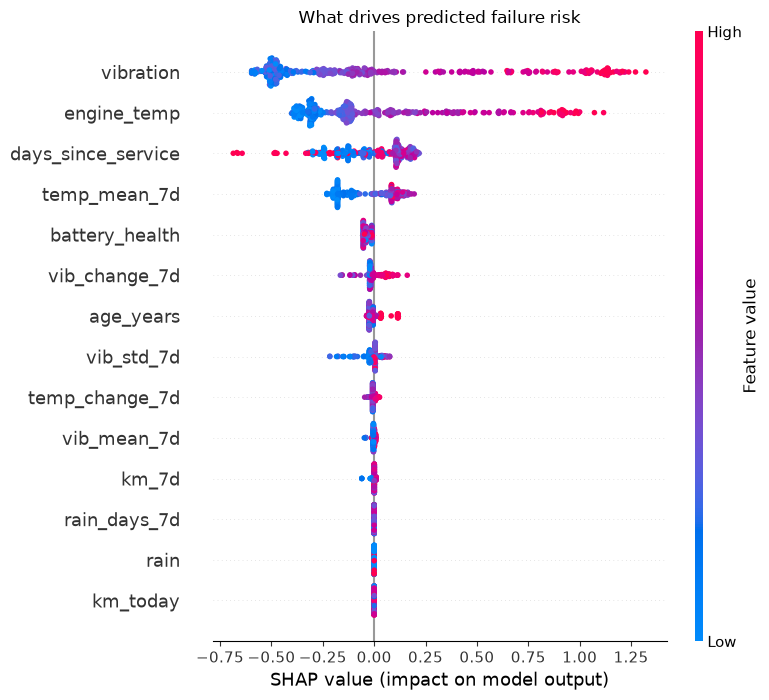

Mean |SHAP| (top 5):
vibration             0.4547
engine_temp           0.3132
days_since_service    0.1462
temp_mean_7d          0.1264
battery_health        0.0335
dtype: float64


In [16]:
try:
    import shap
    tree_model = candidates[FAIL_NAME] if FAIL_NAME in ("Random forest (bagging)", "Gradient boosting (tuned)") else hgb_tuned
    explainer = shap.TreeExplainer(tree_model)
    sample = Xf_te.sample(400, random_state=SEED)
    sv = explainer.shap_values(sample)
    sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if np.ndim(sv) == 3 else sv)
    shap.summary_plot(sv, sample, show=False)
    plt.title("What drives predicted failure risk"); plt.tight_layout()
    SHAP_PNG = ART / "shap_failure.png"
    plt.savefig(SHAP_PNG, dpi=120, bbox_inches="tight"); plt.show()
    shap_rank = pd.Series(np.abs(sv).mean(0), index=sample.columns).sort_values(ascending=False)
    print("Mean |SHAP| (top 5):"); print(shap_rank.head().round(4))
except ImportError:
    SHAP_PNG = None
    print("shap not installed: pip install shap   (skipping)")

## Experiment tracking (MLflow) and saving the selected models

Every run above is logged to MLflow (browse with `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the project folder) and to `05_ml/artifacts/experiments_05a.csv`. The two selected models are saved with a metadata file each: version, input schema, metrics and explanation, as the assignment requires for every learned component.

In [17]:
import hashlib, joblib
def data_hash(df):
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=False).values.tobytes()).hexdigest()[:16]

def save_model(model, key, name, version, features, target, metrics, explanation, train_df):
    path = ART / f"{key}.joblib"
    joblib.dump(model, path, compress=3)   # compressed: ensembles hold many trees
    meta = {"name": name, "version": version, "artifact": path.name,
            "input_schema": {c: str(train_df[c].dtype) for c in features}, "target": target,
            "training_rows": len(train_df), "training_data_hash": data_hash(train_df[features]),
            "test_metrics": {k: round(float(v), 4) for k, v in metrics.items()},
            "explanation": explanation, "selected_by": "cross-validated score on training period"}
    (ART / f"{key}_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    print("saved", path.name, "and", f"{key}_meta.json")

save_model(final_failure, "failure_classifier", f"{FAIL_NAME} + isotonic calibration", "1.0.0",
           pp.FAILURE_FEATURES, pp.FAILURE_TARGET, FAIL_METRICS,
           (f"{SHAP_PNG.relative_to(ROOT).as_posix()} (SHAP of the gradient-boosting model inside the ensemble)"
            if SHAP_PNG else "feature importance in 05a notebook"), f_train)
save_model(final_demand, "demand_forecaster", BEST_REG, "1.0.0", DEM_COLS, pp.DEMAND_TARGET,
           {k: DEM_METRICS[k] for k in ["test_rmse", "test_mae", "test_r2"]}, "residual plots in 05a notebook", d_train)

exp_df = pd.DataFrame(EXPERIMENTS)
exp_df.to_csv(ART / "experiments_05a.csv", index=False)
print(f"Saved {len(exp_df)} runs to experiments_05a.csv")
try:
    import mlflow
    mlflow.set_tracking_uri("sqlite:///" + (ROOT / "mlflow.db").as_posix())
    mlflow.set_experiment("vertexfleet-05a")
    for _, r in exp_df.iterrows():
        with mlflow.start_run(run_name=f"{r.task}: {r.model}"):
            mlflow.log_param("task", r.task)
            for k, v in json.loads(r.params).items():
                mlflow.log_param(k, v)
            for k, v in r.drop(["task", "model", "params"]).dropna().items():
                mlflow.log_metric(k, float(v))
    print(f"Logged {len(exp_df)} runs to MLflow (mlflow.db)")
except ImportError:
    print("mlflow not installed: runs are in the CSV only")
except Exception as e:  # tracking must never block saving models
    print("MLflow logging skipped:", type(e).__name__, str(e)[:120])

from run_meta import write_run_meta
print("Saved", write_run_meta("ml_05a", extra={"failure_model": FAIL_NAME, "demand_model": BEST_REG,
                                              "failure_pr_auc": round(FAIL_METRICS["pr_auc"], 3),
                                              "demand_rmse": round(DEM_METRICS["test_rmse"], 3)}))

saved failure_classifier.joblib and failure_classifier_meta.json
saved demand_forecaster.joblib and demand_forecaster_meta.json
Saved 23 runs to experiments_05a.csv


2026/11/16 20:08:57 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/16 20:08:57 INFO mlflow.store.db.utils: Updating database tables
2026/11/16 20:08:59 INFO mlflow.tracking.fluent: Experiment with name 'vertexfleet-05a' does not exist. Creating a new experiment.
2026/11/16 20:08:59 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|

Logged 23 runs to MLflow (mlflow.db)
Saved C:\Users\David.satizabal001\Documents\ML-1\05_ml\artifacts\ml_05a_run_meta.json


## Findings (generated from this run)

In [18]:
rf_row, raw_row = reg_table.loc[BEST_REG], fe_rows[0]
eng_row, pca_row = fe_rows[1], fe_rows[2]
print(f"""1. Demand: {BEST_REG} wins (test RMSE {rf_row.test_rmse:.3f}, R2 {rf_row.test_r2:.3f}), beating the Phase 1 baseline of 3.527.
2. Failure: best single classifier by CV PR AUC is {clf_table.index[0]}; best overall is {FAIL_NAME} ({all_clf.cv_pr_auc.iloc[0]:.3f}).
3. Alarm cutoff {ALERT_THRESHOLD:.3f} (chosen on training folds) gives test recall {FAIL_METRICS['recall']:.2f} at precision {FAIL_METRICS['precision']:.2f}.
4. Calibration: unweighted logistic is best calibrated (Brier {cal_rows[1]['brier']:.3f}); balanced weights inflate probabilities.
5. Feature engineering: CV PR AUC raw {raw_row['cv_pr_auc']:.3f} vs raw+engineered {eng_row['cv_pr_auc']:.3f} vs PCA {pca_row['cv_pr_auc']:.3f}.
   {"The 7-day features did not help in cross-validation" if eng_row['cv_pr_auc'] <= raw_row['cv_pr_auc'] else "The 7-day features helped"}; PCA needed most components, so the features carry little redundancy.
6. Tuning: Bayesian search reached {tune_table.cv_pr_auc.max():.3f} in the same number of tries as grid and random search.
7. Unsupervised: vehicle usage clusters are weak (best silhouette {k_table.kmeans_silhouette.max():.2f}), because the simulator gives every vehicle a similar usage pattern.
   The GMM rediscovers hidden health from two sensors (ARI {ari:.2f}), and the Isolation Forest flags {rate['Critical']:.0%} of Critical and {rate['Failed']:.0%} of Failed days vs {rate['Healthy']:.0%} of Healthy days.
8. SHAP: the top drivers of failure risk are {', '.join(shap_rank.index[:3]) if SHAP_PNG else 'n/a (shap not installed)'}.""")

1. Demand: Gradient boosting wins (test RMSE 3.255, R2 0.746), beating the Phase 1 baseline of 3.527.
2. Failure: best single classifier by CV PR AUC is Gaussian naive Bayes; best overall is Stacking (logit + RF + HGB) (0.651).
3. Alarm cutoff 0.230 (chosen on training folds) gives test recall 0.70 at precision 0.50.
4. Calibration: unweighted logistic is best calibrated (Brier 0.076); balanced weights inflate probabilities.
5. Feature engineering: CV PR AUC raw 0.623 vs raw+engineered 0.597 vs PCA 0.595.
   The 7-day features did not help in cross-validation; PCA needed most components, so the features carry little redundancy.
6. Tuning: Bayesian search reached 0.628 in the same number of tries as grid and random search.
7. Unsupervised: vehicle usage clusters are weak (best silhouette 0.27), because the simulator gives every vehicle a similar usage pattern.
   The GMM rediscovers hidden health from two sensors (ARI 0.66), and the Isolation Forest flags 52% of Critical and 100% of Fai